# Complete Compton sky reconstruction: active scientific review

This notebook reconstructs **all278 attitudes,60 scatter-angle bins and3072 directions**, with every3072 sky pixel retained. The observations are author-existing simulated satellite data. We reproduce ordinary fixed-background Poisson Richardson–Lucy, not the uncompleted advanced variant. A standard-method reference is available; an independent actual sky truth is not.

The six chapters connect observations, physical count formation, actual inverse updates, source parity, forward consistency and limitations. Every displayed fresh reconstruction is computed below. Frozen original-source measurements are explicitly labeled.

## 1. Observations and calibration

Compton kinematics constrains incoming directions to cones; attitude rotation and response spread one sky pixel over many measurement bins. The event array includes the same injected background realization supplied as ideal known calibration. Thus source counts are events minus that realization, not the difference of two independent Poisson measurements. The selected measured/incident energy interval is509–513keV. Histpy physical-bin extraction excludes original overflow bins, whose nonzero counts remain documented in the private archive; this does not imply zero overflow.

Independent source capture keys: ['maps', 'reconstruction', 'log_likelihood']
Event counts 649141 background 422069


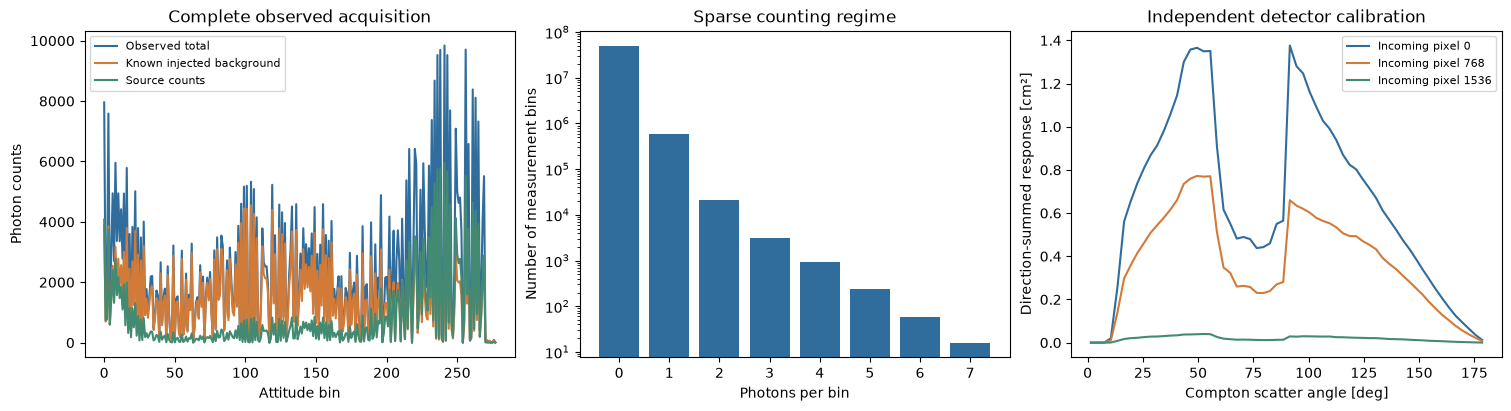

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,tempfile,subprocess,gc
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'): os.environ[key]='1'
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src import visualization as viz
FIGURES=Path(os.environ.get('IMAGING101_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging101_review/compton_attitude_sky_intensity')))
data=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_runs.npz',allow_pickle=False) as archive:
    upstream={key:archive[key].copy() for key in archive.files}
print('Independent source capture keys:',list(upstream))
print('Event counts',int(data.events.sum(dtype=np.uint64)),'background',int(data.background.sum(dtype=np.uint64)))
def show_export(fig,arrays,name,extra=None):
    viz.export_figure(fig,FIGURES/name,arrays,dict(method='Ordinary fixed-background RL; all optional flags disabled',data='Author-existing DC2 satellite simulation, full physical bins',fresh_computed=True,**(extra or {})))
    display(fig);plt.close(fig)
fig,arrays=viz.acquisition_figure(data)
show_export(fig,arrays,'01_acquisition')

## 2. Physical model and active reconstruction

Let $x_j$ denote integrated sky intensity in photons cm$^{-2}$ s$^{-1}$ sr$^{-1}$; $C_{ajk}$ is dwell time in seconds from Galactic pixel$j$ to local incoming direction$k$ at attitude$a$; $R_{kq}$ is response in cm$^2$ for detector bin$q$; $\Omega=4\pi/3072$ sr. The mean count is $\mu_{aq}=b_{aq}+\Omega\sum_kR_{kq}\sum_jC_{ajk}x_j+10^{-12}$, where$b$ is known background. Exposure is$e=A^T1$, where$A$ is the linear source operator.

We maximize the total Poisson log likelihood $\ell=\sum d\log\mu-\sum\mu$, omitting fixed factorials. From a flat$x=10^{-4}$, each update computes$\delta=x[A^T(d/\mu)/e-1]$ and$x\leftarrow\max(0,x+\delta)$. The step is one; there is no smoothing, acceleration, weighting or background fitting. After the second update, a nonnegative likelihood increment below0.01 permits stopping, with a30update budget. Source float32 arithmetic and additive order are retained. Sparse factorization/tiles retain the complete reduction dimensions.

The cell below performs the full selected reconstruction. The original complete30update source run and its independent repeat were bitwise identical. They are stored separately from this computation.

{'iteration': 1, 'log_likelihood': -1543375.5}
{'iteration': 7, 'log_likelihood': -1494478.0}
{'iteration': 15, 'log_likelihood': -1488866.75}
{'iteration': 30, 'log_likelihood': -1487178.5}
Active complete reconstruction seconds: 213.52313819999108


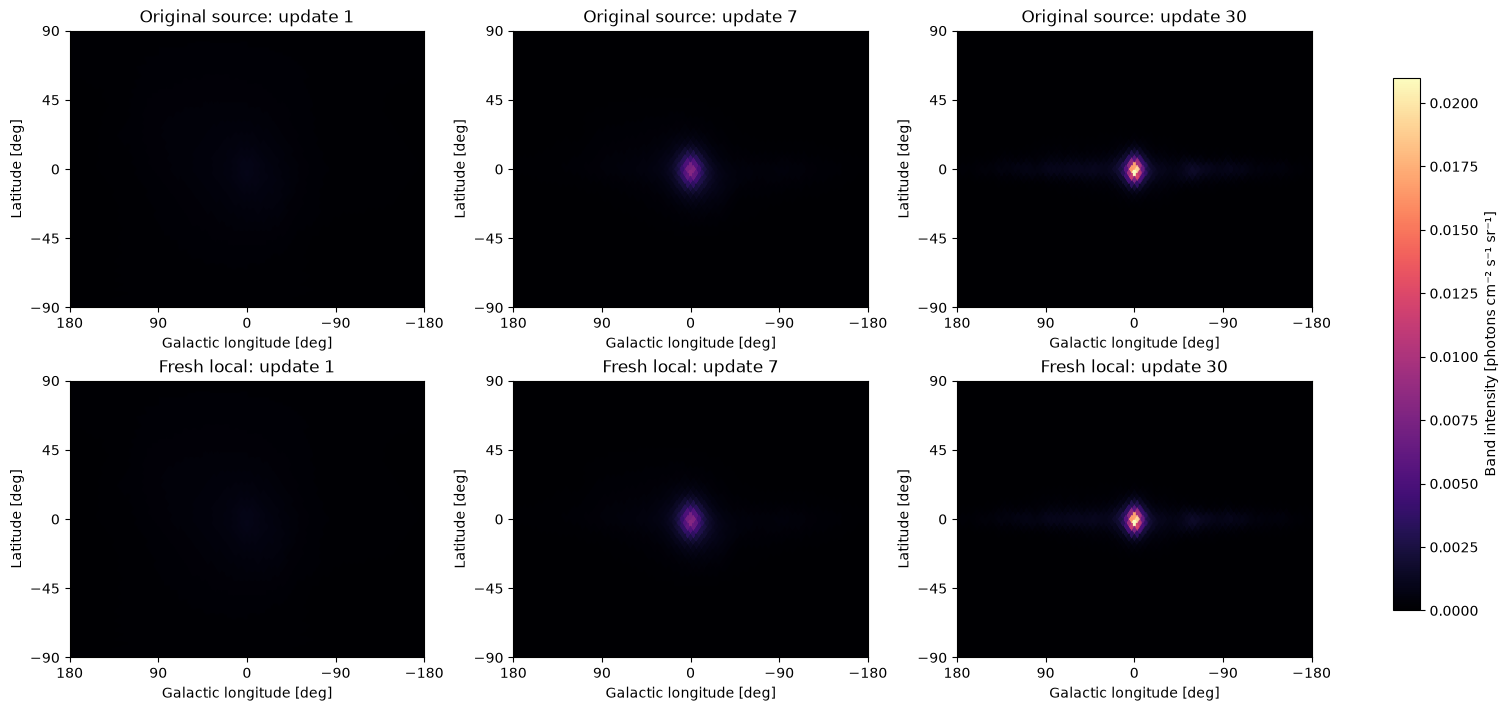

In [2]:
started=time.perf_counter()
progress=[]
def record(iteration,model,delta,likelihood):
    progress.append(dict(iteration=iteration,log_likelihood=likelihood))
    if iteration in (1,7,15,30): print(progress[-1],flush=True)
fresh=reconstruct(data,iterations=30,callback=record)
active_seconds=time.perf_counter()-started
assert len(fresh.maps)==30
print('Active complete reconstruction seconds:',active_seconds)
# Upstream archive names are inspected explicitly, never guessed from filenames.
original_maps=upstream['maps']
original_likelihood=upstream['log_likelihood']
fig,arrays=viz.iteration_figure(fresh,original_maps)
show_export(fig,arrays,'02_iteration_comparison',dict(active_seconds=active_seconds))

## 3. Independent source parity and output contract

The required output is a real nonnegative float32/float64 array$(1,3072)$ in Galactic HEALPix RING order and absolute integrated intensity units. No image alignment, rescaling, cropping or magnitude conversion is allowed. NCC is cosine similarity without mean subtraction; NRMSE is RMS error divided by the reference dynamic range. Frozen numerical gates are NCC$\ge0.999999$ and NRMSE$\le10^{-5}$. They were fixed before extracting the local inverse. We compare the same actual observations, not a different demo.

The signed difference map and all-pixel scatter show both morphology and scale. Original-source results are method references, never labeled truth. Independent source forward/transpose and first-update fixtures are exercised by the test suite; agreement of final images alone does not replace those tests.

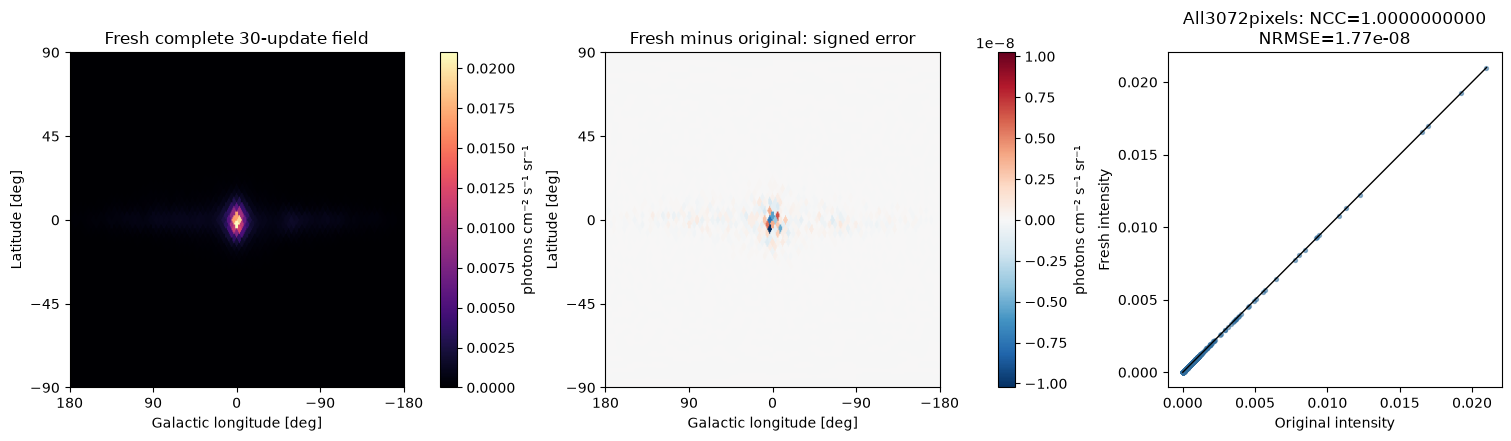

Fresh vs independently reproduced source: {
  "ncc": 0.9999999999999276,
  "nrmse": 1.7742092871240987e-08
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999276,
    "nrmse": 1.7742092871240987e-08,
    "source_count_relative_error": 0.00041252269820016914
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "source_count_relative_error": {
      "comparison": "<=",
      "boundary": 0.001
    }
  },
  "errors": []
}


In [3]:
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as archive:
    reference=archive['reconstruction'].copy()
fig,arrays=viz.parity_figure(fresh,reference)
show_export(fig,arrays,'03_full_field_parity')
metrics=viz.image_metrics(fresh.reconstruction,reference)
print('Fresh vs independently reproduced source:',json.dumps(metrics,indent=2))
all_update_errors=[viz.image_metrics(a,b)['nrmse'] for a,b in zip(fresh.maps,original_maps)]
assert max(all_update_errors)<1e-5
destination=ROOT/'output/reconstruction.npz';destination.parent.mkdir(exist_ok=True)
np.savez_compressed(destination,reconstruction=fresh.reconstruction)
judge=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(destination),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert judge.returncode==0,(judge.returncode,judge.stderr)
report=json.loads((ROOT/'output/judge_report.json').read_text())
print(json.dumps(report,indent=2))

## 4. Forward consistency and approximation limits

Fold the **fresh** intensity through the complete calibrated operator. Integrated source-count closure is $|e^T\hat x-\sum(d-b)|/\sum(d-b)$ and must be$\le0.001$. This is sensitive to physical scale even when cosine similarity is one. All bins enter totals; only the lower residual display restricts bins to expected counts$\ge20$ for a normal approximation.

Finite Monte Carlo response and averaged attitudes approximate the acquisition. The independently reproduced source had attitude Pearson/bin2.4745, scatter-angle1.3206 and scattered-direction1.0595; source-count closure0.000412573. These residual summaries show overdispersion in attitude. They are descriptive diagnostics, not calibrated p-values or proof of sky truth. A private independent sparse-Poisson calculation also found a discrepancy of about6.4 fixed-mean standard deviations for the fitted-model deviance; fitting and response approximation prevent interpreting this as an exact null-test significance.

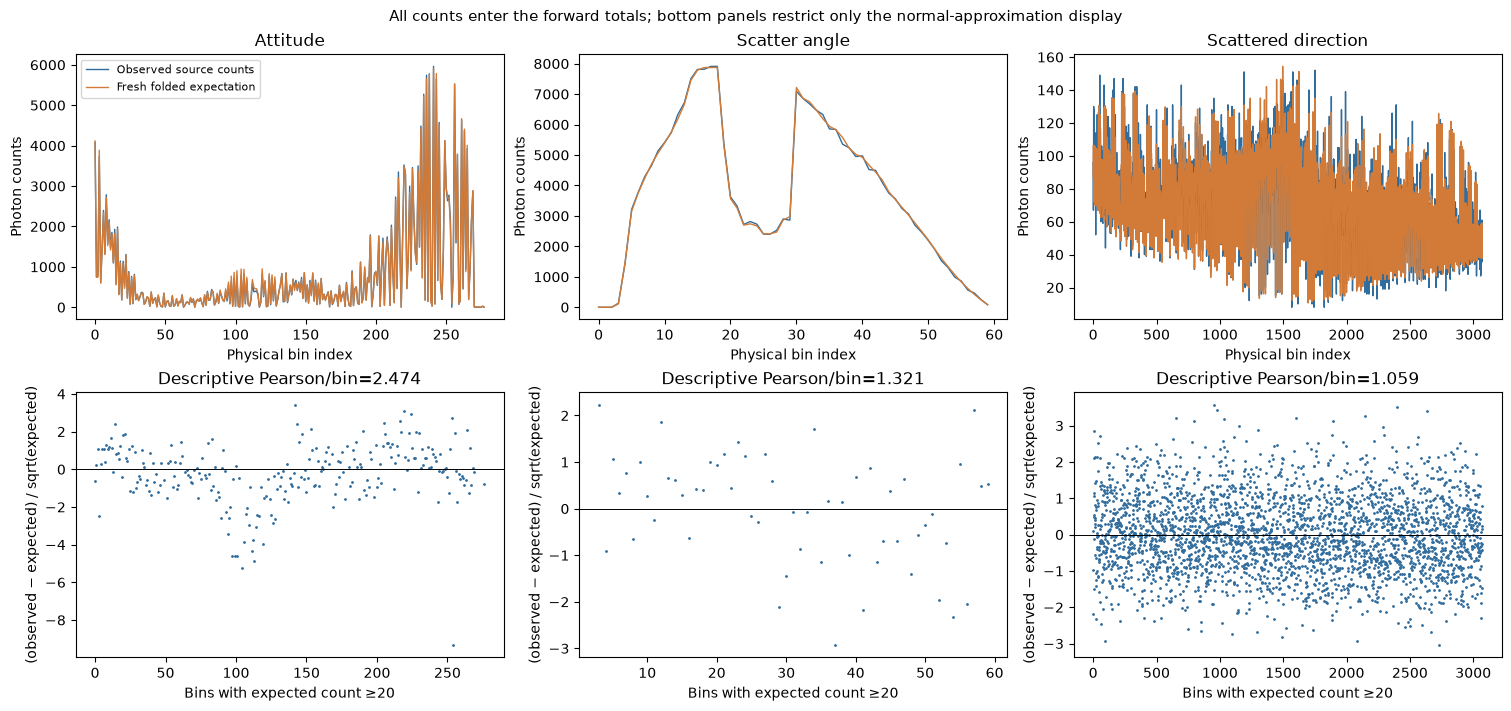

{
  "Attitude": {
    "pearson_per_bin": 2.4744787818885006,
    "counts_covered": 0.9994010710259301
  },
  "Scatter angle": {
    "pearson_per_bin": 1.320571812235385,
    "counts_covered": 1.0
  },
  "Scattered direction": {
    "pearson_per_bin": 1.0594843791588877,
    "counts_covered": 0.9980975197294251
  }
}


40549

In [4]:
source_expectation=data.operator.forward(fresh.reconstruction,add_floor=False)
fig,arrays,forward_statistics=viz.forward_figure(data,source_expectation)
show_export(fig,arrays,'04_forward_consistency',dict(statistics=forward_statistics))
print(json.dumps(forward_statistics,indent=2))
del source_expectation;gc.collect()

## 5. Convergence and finite-iteration sensitivity

Compare original-source and newly measured total log likelihood on identical observations. Integrated source flux is $\Omega\sum_jx_j$ in photons cm$^{-2}$s$^{-1}$. The last panel compares each fresh update with the **original update30**, so it reports finite-iteration sensitivity rather than physical error. This prevents early or over-smoothed updates from being confused with the selected finite-iteration benchmark.

The source plain-dictionary configuration originally mislabeled two basic runs as advanced. Audit showed the optional flags were false. Correcting the wrapper caused the real advanced before/after expectation copy to exceed resources; all failed capture histories remain private. This benchmark was explicitly rebound to published ordinary fixed-background RL before local inverse implementation. There is no completed advanced curve or missing method filled with a reference.

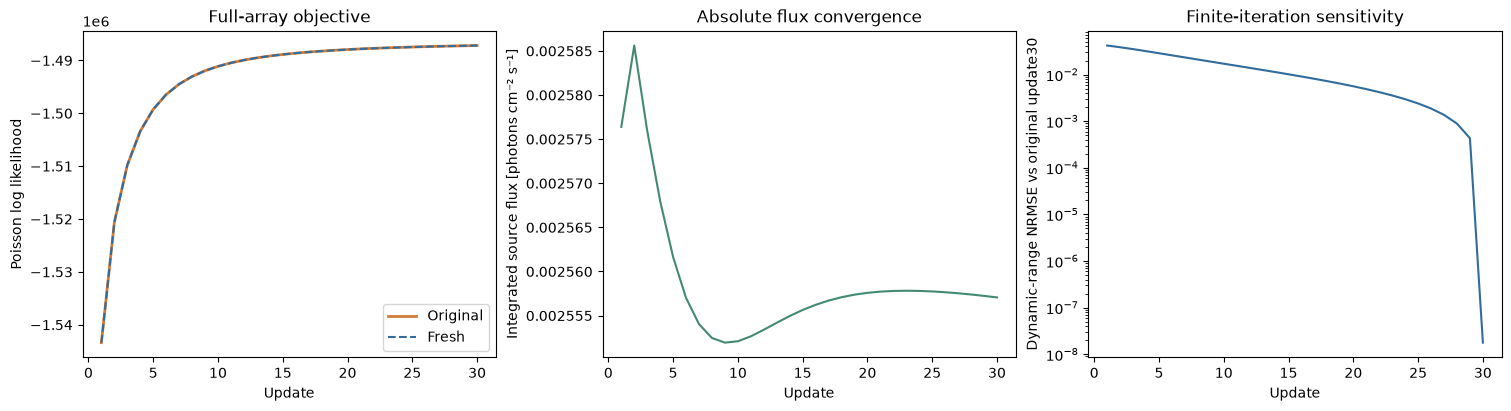

In [5]:
fig,arrays=viz.convergence_figure(fresh,original_maps,original_likelihood)
show_export(fig,arrays,'05_convergence')

## 6. Negative controls and conclusion

Zero, flat, five-percent scale error and permuted maps test different failure modes. Cosine similarity alone cannot reject a scale error, so the absolute image and source-count criteria remain required. Every gate must pass; the rejected controls are computed from actual arrays.

The result establishes reproduction of the selected published ordinary method on this complete bound acquisition, within predeclared float32 tolerance, together with independent operator/transpose/dwell tests and count-scale closure. Its limits are ideal known injected background, finite response simulation and averaged orientation, absence of independent sky truth, and residual overdispersion. Successful reference reproduction is evidence of implementation parity, not complete physical accuracy.

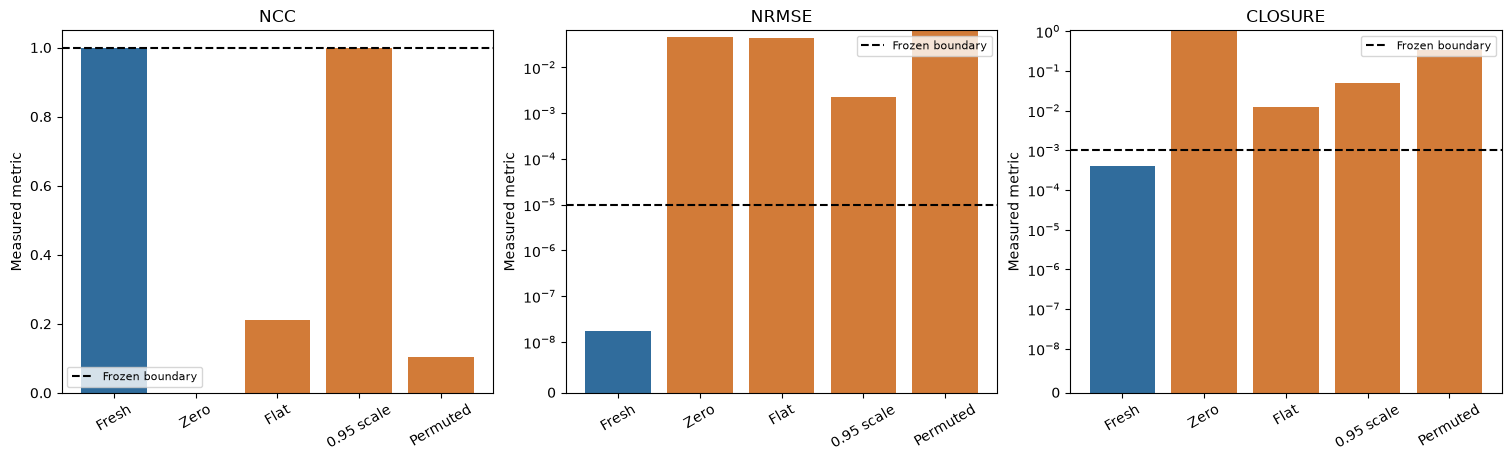

Fresh {'ncc': 0.9999999999999276, 'nrmse': 1.7742092871240987e-08, 'source_count_closure': 0.00041252269820016914, 'passed': True}
Zero {'ncc': 0.0, 'nrmse': 0.04602289441367842, 'source_count_closure': 1.0, 'passed': False}
Flat {'ncc': 0.21059178950217303, 'nrmse': 0.04499078904923131, 'source_count_closure': 0.012398236213459472, 'passed': False}
0.95 scale {'ncc': 0.9999999999999303, 'nrmse': 0.0023011476702223675, 'source_count_closure': 0.04960811532561734, 'passed': False}
Permuted {'ncc': 0.1025459416335041, 'nrmse': 0.061658793982473585, 'source_count_closure': 0.342532289211128, 'passed': False}
Scientific review complete; actual active runtime 213.52313819999108 seconds; six figures in D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\groups\physics_materials\cosi\final_figures


In [6]:
source_count=int(data.events.sum(dtype=np.uint64))-int(data.background.sum(dtype=np.uint64))
fig,arrays=viz.negative_controls_figure(fresh,reference,data.operator.exposure,source_count)
show_export(fig,arrays,'06_negative_controls')
for idx,label in enumerate(['Fresh','Zero','Flat','0.95 scale','Permuted']):
    passes=bool(arrays['ncc'][idx]>=.999999 and arrays['nrmse'][idx]<=1e-5 and arrays['source_count_closure'][idx]<=.001)
    print(label,dict(ncc=float(arrays['ncc'][idx]),nrmse=float(arrays['nrmse'][idx]),source_count_closure=float(arrays['source_count_closure'][idx]),passed=passes))
    assert passes==(idx==0)
measurements=ROOT/'notebooks/reference_outputs/fresh_review_measurements.npz'
np.savez_compressed(measurements,maps=fresh.maps,log_likelihood=fresh.log_likelihood,reconstruction=fresh.reconstruction,active_seconds=np.asarray(active_seconds))
print('Scientific review complete; actual active runtime',active_seconds,'seconds; six figures in',FIGURES)